# Submission 3: Custom CNN from scratch
**Dataset:** SCAB benchmark (original images, Scabies vs Healthy)
**Model:** small CNN trained from scratch (4 conv blocks)
**Outputs:** accuracy and loss curves, classification report, test confusion matrix, training and testing time

## 0. Colab setup
Mounts Google Drive and unzips the images. `SCAB_original.zip` and `SCAB_metadata_CSV.csv` must be in the top level of My Drive.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!rm -rf /content/data
!mkdir -p /content/data
!unzip -q "/content/drive/MyDrive/SCAB_original.zip" -d /content/data
!ls /content/data

Mounted at /content/drive
SCAB_original


## 1. Imports

In [2]:
import os, time, random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import layers, models, callbacks

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))

2.21.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Settings
Batch size 32, Adam, learning rate 1e-3, at most 50 epochs. These stay the same for the whole notebook.

In [3]:
DATA_ROOT = '/content/data'
CSV_PATH = '/content/drive/MyDrive/SCAB_metadata_CSV.csv'

IMG = 224
BATCH = 32
EPOCHS = 50
PATIENCE = 8
LR = 1e-3
CLASS_NAMES = ['Healthy', 'Scabies']

## 3. Match the CSV to the image files
Same as Submission 2. The table at the end should show Healthy only in the healthy folder and Scabies only in the Scabies folder.

In [4]:
index = {}
for root, dirs, files in os.walk(DATA_ROOT):
    if '__MACOSX' in root:
        continue
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')) and not f.startswith('._'):
            index[f] = os.path.join(root, f)
print('Images found in zip:', len(index))

df = pd.read_csv(CSV_PATH)
df = df.dropna(subset=['Image_id'])
df = df[['Image_id', 'Class Label']].copy()
df.columns = ['image', 'class_name']

df['patient'] = df['image'].str.extract(r'^(PAT_\d+)')[0]
df['label'] = (df['class_name'] == 'Scabies').astype(int)
df['path'] = df['image'].map(index)
df['folder'] = df['path'].map(lambda p: os.path.basename(os.path.dirname(p)) if isinstance(p, str) else None)

print('Total images in CSV:', len(df))
print('Missing files:', df['path'].isna().sum())
assert df['path'].notna().all(), 'Some CSV images were not found in the unzipped folder'
pd.crosstab(df['folder'], df['class_name'])

Images found in zip: 606
Total images in CSV: 606
Missing files: 0


class_name,Healthy,Scabies
folder,,
Scabies,0,406
healthy,200,0


## 4. Train / validation / test split (by patient)
Same split as Submission 2: 70% train, 15% validation, 15% test, split by patient.

In [5]:
patients = df.groupby('patient', as_index=False)['label'].first()

train_p, temp_p = train_test_split(patients, test_size=0.30, stratify=patients['label'], random_state=SEED)
val_p, test_p = train_test_split(temp_p, test_size=0.50, stratify=temp_p['label'], random_state=SEED)

train_df = df[df['patient'].isin(train_p['patient'])]
val_df = df[df['patient'].isin(val_p['patient'])]
test_df = df[df['patient'].isin(test_p['patient'])]

summary = pd.DataFrame({
    'Split': ['Train', 'Validation', 'Test'],
    'Patients': [len(train_p), len(val_p), len(test_p)],
    'Images': [len(train_df), len(val_df), len(test_df)],
    'Healthy': [(d['label'] == 0).sum() for d in (train_df, val_df, test_df)],
    'Scabies': [(d['label'] == 1).sum() for d in (train_df, val_df, test_df)],
})
print('Patient overlap train/test:', len(set(train_p['patient']) & set(test_p['patient'])))
summary

Patient overlap train/test: 0


,Split,Patients,Images,Healthy,Scabies
0,Train,118,423,140,283
1,Validation,25,92,27,65
2,Test,26,91,33,58


## 5. Build the data pipelines
Images are resized to 224x224. Scaling to 0-1 and augmentation happen inside the model (augmentation only in training). Class weights handle the imbalance.

In [6]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG, IMG))
    return img, tf.cast(label, tf.float32)

def make_ds(d, train=False):
    ds = tf.data.Dataset.from_tensor_slices((d['path'].values, d['label'].values))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if train:
        ds = ds.shuffle(len(d), seed=SEED)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_df, train=True)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)

y_train = train_df['label'].values
y_test = test_df['label'].values

weights = len(y_train) / (2 * np.bincount(y_train))
class_weight = {0: weights[0], 1: weights[1]}
print('Class weights:', class_weight)

Class weights: {0: np.float64(1.5107142857142857), 1: np.float64(0.7473498233215548)}


## 6. Custom CNN
Augmentation, rescale, 4 blocks of (Conv, BatchNorm, ReLU, MaxPool) with 32, 64, 128 and 256 filters, global average pooling, Dense(128), Dropout, one sigmoid output.

In [7]:
augment = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same')(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.ReLU()(x)
    return layers.MaxPooling2D()(x)

def build_cnn():
    inputs = layers.Input((IMG, IMG, 3))
    x = augment(inputs)
    x = layers.Rescaling(1.0 / 255)(x)
    for f in [32, 64, 128, 256]:
        x = conv_block(x, f)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    model = models.Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(LR), loss='binary_crossentropy', metrics=['accuracy'])
    return model

build_cnn().summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

## 7. Train and evaluate
Early stopping watches validation loss with patience 8 and cannot stop before epoch 5. The best weights are restored at the end. Training time is the time for `model.fit`, testing time is the time to predict the test set.

In [8]:
def run(title='Custom CNN'):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_cnn()
    cbs = [callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, start_from_epoch=5, restore_best_weights=True)]

    start = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                     class_weight=class_weight, callbacks=cbs, verbose=2)
    train_seconds = time.time() - start

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist.history['accuracy'], label='Train')
    ax[0].plot(hist.history['val_accuracy'], label='Validation')
    ax[0].set_title(f'{title}: Accuracy')
    ax[0].set_xlabel('Epoch')
    ax[0].set_ylabel('Accuracy')
    ax[0].legend()
    ax[1].plot(hist.history['loss'], label='Train')
    ax[1].plot(hist.history['val_loss'], label='Validation')
    ax[1].set_title(f'{title}: Loss')
    ax[1].set_xlabel('Epoch')
    ax[1].set_ylabel('Loss')
    ax[1].legend()
    plt.tight_layout()
    plt.show()

    start = time.time()
    y_prob = model.predict(test_ds, verbose=0).ravel()
    test_seconds = time.time() - start
    y_pred = (y_prob > 0.5).astype(int)

    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap='Blues')
    plt.title(f'{title}: Test confusion matrix')
    plt.show()

    rep = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    return {
        'Model': title,
        'Epochs Run': len(hist.history['loss']),
        'Parameters': model.count_params(),
        'Test Acc': round(rep['accuracy'], 4),
        'Precision': round(rep['macro avg']['precision'], 4),
        'Recall': round(rep['macro avg']['recall'], 4),
        'F1': round(rep['macro avg']['f1-score'], 4),
        'Train Time (min)': round(train_seconds / 60, 2),
        'Test Time (sec)': round(test_seconds, 2),
    }

## 8. Run the custom CNN

Epoch 1/50
14/14 - 20s - 1s/step - accuracy: 0.8227 - loss: 0.3780 - val_accuracy: 0.7065 - val_loss: 0.5813
Epoch 2/50
14/14 - 2s - 147ms/step - accuracy: 0.8936 - loss: 0.2513 - val_accuracy: 0.9022 - val_loss: 0.3060
Epoch 3/50
14/14 - 2s - 174ms/step - accuracy: 0.9102 - loss: 0.2022 - val_accuracy: 0.8913 - val_loss: 0.2682
Epoch 4/50
14/14 - 2s - 135ms/step - accuracy: 0.9385 - loss: 0.1699 - val_accuracy: 0.9130 - val_loss: 0.1965
Epoch 5/50
14/14 - 2s - 132ms/step - accuracy: 0.9433 - loss: 0.1374 - val_accuracy: 0.9565 - val_loss: 0.1050
Epoch 6/50
14/14 - 2s - 134ms/step - accuracy: 0.9220 - loss: 0.1666 - val_accuracy: 0.4022 - val_loss: 2.6464
Epoch 7/50
14/14 - 2s - 131ms/step - accuracy: 0.9574 - loss: 0.1231 - val_accuracy: 0.7935 - val_loss: 0.6242
Epoch 8/50
14/14 - 2s - 132ms/step - accuracy: 0.9196 - loss: 0.1762 - val_accuracy: 0.8804 - val_loss: 0.2353
Epoch 9/50
14/14 - 2s - 134ms/step - accuracy: 0.9504 - loss: 0.1133 - val_accuracy: 0.8261 - val_loss: 0.2560
Epo

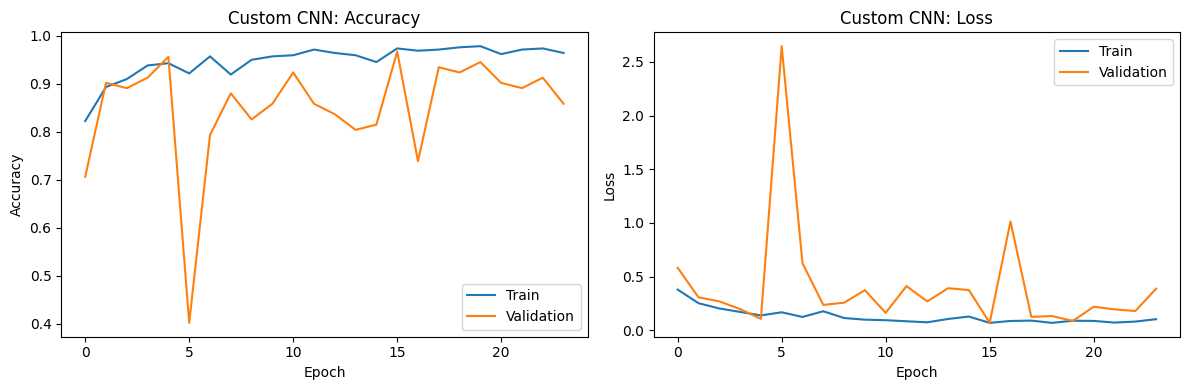

              precision    recall  f1-score   support

     Healthy     0.8684    1.0000    0.9296        33
     Scabies     1.0000    0.9138    0.9550        58

    accuracy                         0.9451        91
   macro avg     0.9342    0.9569    0.9423        91
weighted avg     0.9523    0.9451    0.9458        91



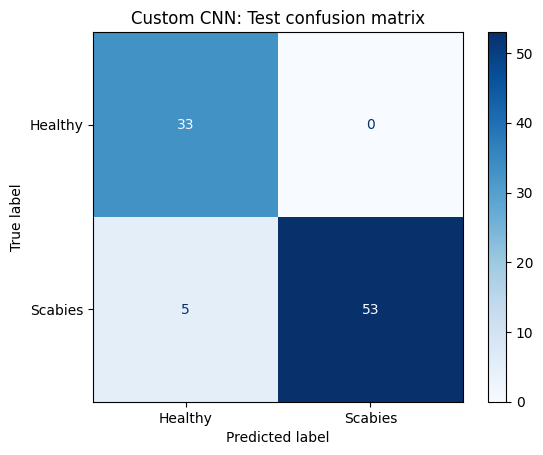

,Model,Epochs Run,Parameters,Test Acc,Precision,Recall,F1,Train Time (min),Test Time (sec)
0,Custom CNN,24,423361,0.9451,0.9342,0.9569,0.9423,1.07,1.95


In [9]:
result = run('Custom CNN')
pd.DataFrame([result])

## 9. Conclusion
The custom CNN reached a test accuracy of 0.9451, with precision 0.9342, recall 0.9569 and F1 0.9423. Early stopping ended training at epoch 24 and restored the weights from epoch 16, where validation accuracy was 0.9674. Training took 1.07 minutes and testing took 1.95 seconds.

On the test set the model got all 33 Healthy images right and missed 5 of the 58 Scabies images, so every error is a Scabies image predicted as Healthy. At the best epoch training accuracy (0.9740) and validation accuracy (0.9674) are close, so there is no clear overfitting. The validation curve jumps a lot from epoch to epoch because the validation set is small (92 images from 25 patients).

Limitations: the test set has only 91 images, so one image changes accuracy by about 1.1 points. In this dataset the Healthy and Scabies photos were taken in different settings, so the model may partly use the background and not only the skin. These scores should not be read as clinical performance.